# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: ano section niyo hehe

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

Grid with random spins 20x20

step 1, random lattice of spin ups and spin downs
pick random lattice and flip sign then calculate new energy (Hamiltonian)

1 seep is $N^2$ flips

`np.roll = wrap around`

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

In [2]:
# creating the grid
np.random.seed(67)

# setup

N = 20 # lattice size
J = 1.0 # interaction strength
kB = 1.0 # Boltzmann Constant

# initializing lattice with random -1 or 1

def initialize_lattice(N):
    return np.random.choice([-1, 1], size=(N, N))

initialize_lattice(N)

array([[ 1,  1, -1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1, -1,  1,
         1, -1, -1, -1],
       [ 1,  1, -1,  1,  1, -1, -1, -1,  1,  1, -1, -1,  1, -1,  1,  1,
         1,  1, -1, -1],
       [ 1, -1, -1, -1,  1, -1, -1, -1,  1,  1, -1, -1, -1, -1, -1, -1,
        -1, -1,  1, -1],
       [-1,  1,  1,  1,  1,  1, -1, -1,  1, -1,  1, -1,  1, -1, -1,  1,
         1,  1,  1,  1],
       [-1, -1,  1,  1,  1,  1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1,
         1, -1,  1, -1],
       [-1, -1,  1, -1, -1,  1, -1, -1, -1, -1,  1,  1,  1,  1,  1, -1,
        -1, -1,  1,  1],
       [ 1, -1,  1, -1, -1, -1, -1,  1, -1, -1, -1,  1,  1, -1, -1, -1,
         1, -1, -1,  1],
       [ 1,  1, -1,  1, -1,  1,  1, -1, -1,  1,  1,  1, -1,  1,  1,  1,
        -1, -1, -1, -1],
       [-1,  1,  1,  1,  1, -1, -1,  1, -1, -1, -1, -1, -1,  1,  1,  1,
         1,  1,  1, -1],
       [ 1, -1, -1,  1,  1, -1,  1, -1, -1, -1, -1, -1, -1, -1,  1, -1,
        -1,  1, -1,  1],
       [-1, -1, -1,  1, -1,  1

In [3]:
# calculating total energy

def calculate_total_energy(lattice, J=1.0, B=0.0): # J is the spin-spin constant and B is the magnetic field strength
    neighbor_right = np.roll(lattice, -1, axis=1)
    neighbor_down = np.roll(lattice, -1, axis=0)

    # adds right and down neighbors (i,j) for every site then multiplies the sum by -J to get interaction energy
    interaction_energy = -J * np.sum(lattice * (neighbor_right + neighbor_down))
    # calculates net spin sum across all sites and multiplies sum by -B
    field_energy = -B * np.sum(lattice)

    return interaction_energy + field_energy # this is our Hamiltonian energy H

def calculate_magnetization(lattice):
    return np.mean(lattice)

Initialized Lattice: [[ 1  1 -1  1  1  1  1  1  1 -1  1  1  1  1 -1  1  1 -1 -1 -1]
 [ 1  1 -1  1  1 -1 -1 -1  1  1 -1 -1  1 -1  1  1  1  1 -1 -1]
 [ 1 -1 -1 -1  1 -1 -1 -1  1  1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1]
 [-1  1  1  1  1  1 -1 -1  1 -1  1 -1  1 -1 -1  1  1  1  1  1]
 [-1 -1  1  1  1  1 -1  1 -1  1 -1  1 -1  1 -1  1  1 -1  1 -1]
 [-1 -1  1 -1 -1  1 -1 -1 -1 -1  1  1  1  1  1 -1 -1 -1  1  1]
 [ 1 -1  1 -1 -1 -1 -1  1 -1 -1 -1  1  1 -1 -1 -1  1 -1 -1  1]
 [ 1  1 -1  1 -1  1  1 -1 -1  1  1  1 -1  1  1  1 -1 -1 -1 -1]
 [-1  1  1  1  1 -1 -1  1 -1 -1 -1 -1 -1  1  1  1  1  1  1 -1]
 [ 1 -1 -1  1  1 -1  1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1  1 -1  1]
 [-1 -1 -1  1 -1  1 -1  1 -1  1  1  1 -1 -1  1 -1 -1 -1  1  1]
 [ 1 -1  1  1  1  1 -1  1 -1  1  1 -1 -1  1 -1  1  1 -1  1 -1]
 [-1  1 -1  1 -1 -1  1 -1  1  1  1 -1  1  1 -1  1  1  1 -1 -1]
 [-1  1 -1 -1  1  1 -1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1  1]
 [-1 -1  1  1  1 -1  1  1 -1 -1  1 -1 -1  1 -1 -1 -1  1  1 -1]
 [ 1  1 -1  1  1  1  1 -1  1  1 -1

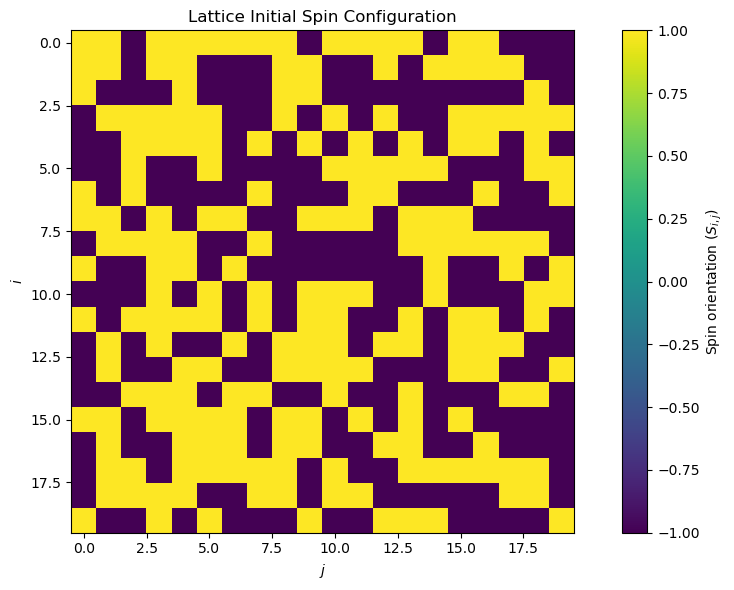

Total Energy: 20.0
Magnetization: 0.01


In [4]:
np.random.seed(67)

lattice_init = initialize_lattice(N)
E_init = calculate_total_energy(lattice_init)
m_init = calculate_magnetization(lattice_init)

print("Initialized Lattice:",lattice_init)

# plot our initial boi

plt.figure(figsize=(10, 6))
plt.title("Lattice Initial Spin Configuration")
plt.imshow(lattice_init)
plt.colorbar(label='Spin orientation ($S_{i,j}$)')
plt.xlabel("$j$")
plt.ylabel("$i$")
plt.tight_layout()
plt.show()

print("Total Energy:",E_init)
print("Magnetization:",m_init)

In [5]:
# flip on lattice and calculate new energy (lattice sweep, attemp to flip all lattices)
# parameters
N = 20
sweeps = 10000
T = 1.0
J = 1.0
B = 0.0
lattice=None

def ising_simulation(N=N, sweeps=sweeps, T=T, J=J, B=B, lattice=lattice):
    # code for if you want to use another lattice
    if lattice is None:
        lattice = initialize_lattice(N)
    else:
        lattice = lattice.copy()

    # counts amount of spaces
    num_spins = N * N

    # sets all energies and magnetizations to 0 and creates an array using this temporary value
    energies = np.zeros(sweeps)
    magnetizations = np.zeros(sweeps)

    # computes the baseline energy
    current_energy = calculate_total_energy(lattice, J=J, B=B)

    for sweep in range(sweeps):
        for _ in range(num_spins):
            # selects random lattice and obtains its spin
            i = np.random.randint(0, N)
            j = np.random.randint(0, N)
            S_ij = lattice[i, j]

            # sums up the neighbors, modulo N is used to ensure that we do not compare neighbors that are out of bounds and instead wrap around to index 0)
            nn_sum = (lattice[(i + 1) % N, j] + # calculates down neighbor
                      lattice[(i - 1) % N, j] + # calculates top neighbor
                      lattice[i, (j + 1) % N] + # calculates right neighbor
                      lattice[i, (j - 1) % N]) # calculates left neighbor

            # calculate local sum
            delta_H = 2.0 * S_ij * (J * nn_sum + B)

            # if the flip makes the energy lower or the same value we keep the flip
            # this is where we have the flip probability thing
            if delta_H <= 0 or np.random.rand() < np.exp(-delta_H / (kB * T)):
                # flips sign
                lattice[i, j] = -S_ij
                # updates energy
                current_energy += delta_H

        # record the new change
        energies[sweep] = current_energy
        magnetizations[sweep] = np.mean(lattice)

    return lattice, energies, magnetizations

In [6]:
# running the simulation at J = T = kB = 1 and 10000 sweeps
ising_simulation(N, sweeps, T, J, B, lattice)

(array([[-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1],
        [-

In [12]:
# investigating spontaneoous magnetization

sweeps = 5000

# running simulation for low temp T = 1 and B = 0
lattice_T1_run1, E_T1_run1, m_T1_run1 = ising_simulation(N=N, sweeps=sweeps, T=1.0, B=0.0)
lattice_T1_run2, E_T1_run2, m_T1_run2 = ising_simulation(N=N, sweeps=sweeps, T=1.0, B=0.0)

In [8]:
# investigating what happens when External Magnetic Field is introduced with B value at 0.5

sweeps = 5000

# running simulation for low temp T = 1 and B = 0.5
lattice_B05, E_B05, m_B05 = ising_simulation(N=N, sweeps=sweeps, T=1.0, B=0.5)

In [9]:
# investigating spontaneoous magnetization above critical temperature T = 2.269

sweeps = 5000

# running simulation for high temp T = 3.5 and B = 0.0
lattice_highB0, E_highB0, m_highB0 = ising_simulation(N=N, sweeps=sweeps, T=3.5, B=0.5)

In [10]:
# investigating introduction of external magnetic field above critical temperature T = 2.269

sweeps = 5000

# running simulation for high temp T = 3.5 and B = 0.5
lattice_highB05, E_highB05, m_highB05 = ising_simulation(N=N, sweeps=sweeps, T=3.5, B=0.5)

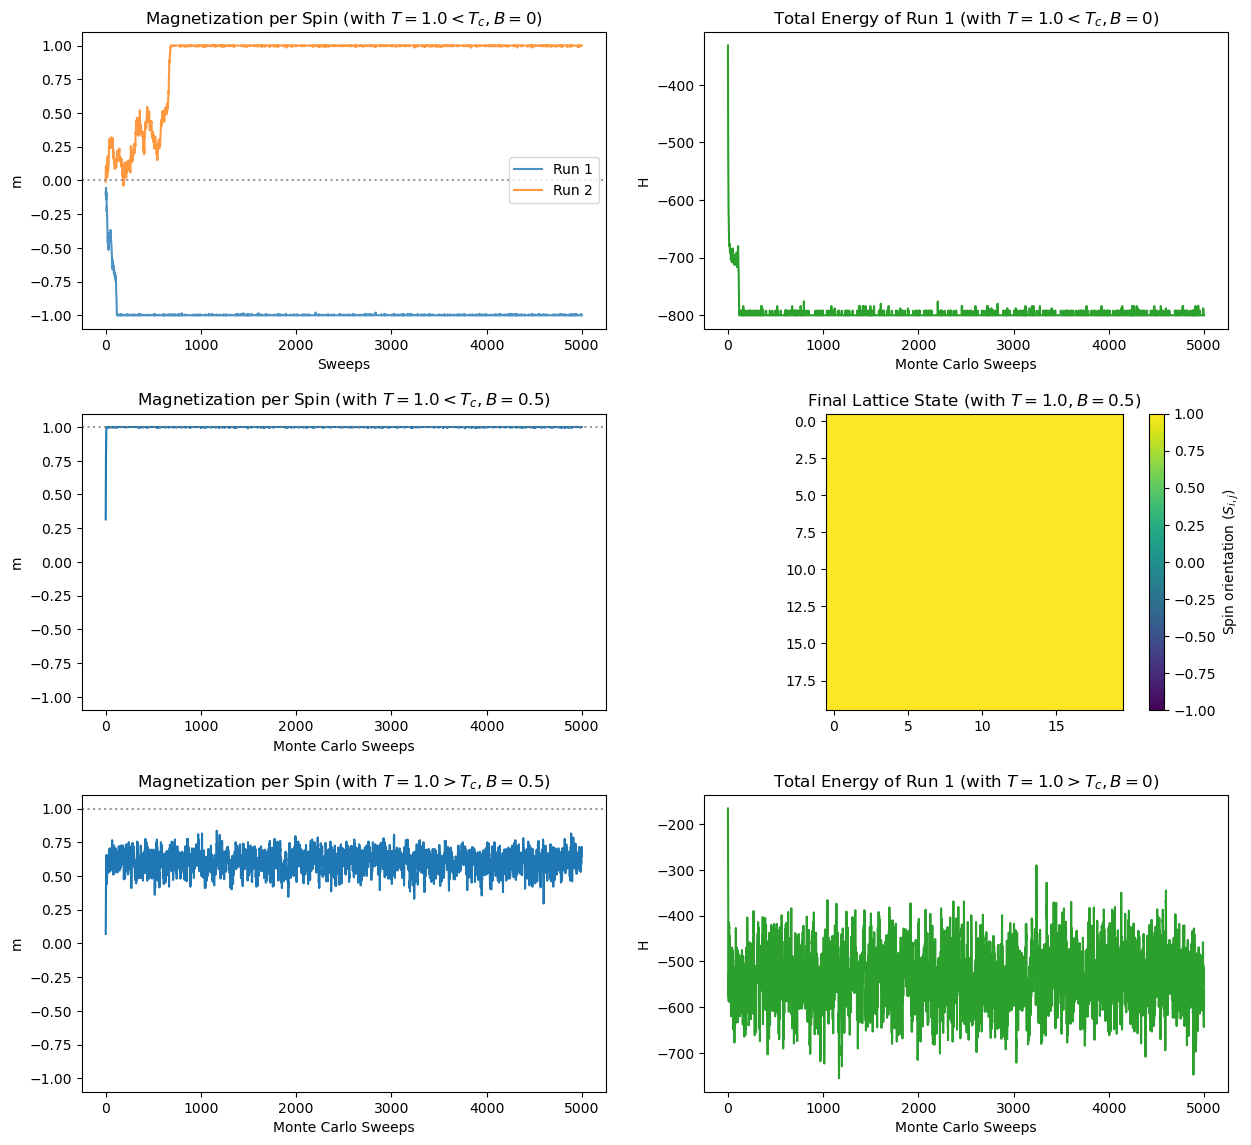

<Figure size 640x480 with 0 Axes>

In [14]:
# visualizing and plotting out stuffsssss

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
fig.tight_layout(pad=4.0)

# plotting spontaneous magnetization with two different initial conditions

axes[0, 0].plot(m_T1_run1, label='Run 1', alpha=0.8)
axes[0, 0].plot(m_T1_run2, label='Run 2', alpha=0.8)
axes[0, 0].axhline(0, color='gray', linestyle=':', alpha=0.8)
axes[0, 0].set_title("Magnetization per Spin (with $T=1.0 < T_c, B=0$)")
axes[0, 0].set_xlabel("Sweeps")
axes[0, 0].set_ylabel("m")
axes[0, 0].set_ylim(-1.1, 1.1)
axes[0, 0].legend()

axes[0, 1].plot(E_T1_run1, label='Run 1', color='tab:green')
axes[0, 1].set_title("Total Energy of Run 1 (with $T=1.0 < T_c, B=0$)")
axes[0, 1].set_xlabel("Monte Carlo Sweeps")
axes[0, 1].set_ylabel("H")

# plotting what happesn when external Mfield is introduced

axes[1, 0].plot(m_B05)
axes[1, 0].axhline(1.0, color='gray', linestyle=':', alpha=0.8)
axes[1, 0].set_title("Magnetization per Spin (with $T=1.0 < T_c, B=0.5$)")
axes[1, 0].set_xlabel("Monte Carlo Sweeps")
axes[1, 0].set_ylabel("m")
axes[1, 0].set_ylim(-1.1, 1.1)

axes[1, 1].imshow(lattice_B05, vmin=-1, vmax=1)
im = axes[1, 1].imshow(lattice_B05, vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[1, 1], label='Spin orientation ($S_{i,j}$)')
axes[1, 1].set_title("Final Lattice State (with $T=1.0, B=0.5$)")

# plotting graphs when ran with temperature over critical levels

axes[2, 0].plot(m_highB0)
axes[2, 0].axhline(1.0, color='gray', linestyle=':', alpha=0.8)
axes[2, 0].set_title("Magnetization per Spin (with $T=1.0 > T_c, B=0.5$)")
axes[2, 0].set_xlabel("Monte Carlo Sweeps")
axes[2, 0].set_ylabel("m")
axes[2, 0].set_ylim(-1.1, 1.1)

axes[2, 1].plot(E_highB0, label='Run 1', color='tab:green')
axes[2, 1].set_title("Total Energy of Run 1 (with $T=1.0 > T_c, B=0$)")
axes[2, 1].set_xlabel("Monte Carlo Sweeps")
axes[2, 1].set_ylabel("H")

plt.show()
plt.savefig('Figure 1.png')